# Fashion-MNIST 모델 비교

CNN 구조에 따른 검증 정확도·손실·학습 시간 비교.

학습 55,000장 / 검증 5,000장 / 테스트 10,000장. 각 모델을 30 epochs 학습하고 마지막 epoch의 검증 정확도로 모델 선택. 선택이 끝난 모델만 테스트 데이터로 최종 평가.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist


np.set_printoptions(precision=3, suppress=True) # 출력보정
tf.random.set_seed(7)# TensorFlow 랜덤 초기값 고정

## 2. 데이터 로드 및 전처리

In [2]:
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = fashion_mnist.load_data()

# label name of Fashion MNIST Dataset
label_name = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
              'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
class_names = label_name

x_train_all = x_train_raw.astype('float32') / 255.0
x_test = x_test_raw.astype('float32') / 255.0
y_train_all = keras.utils.to_categorical(y_train_raw, 10)
y_test = keras.utils.to_categorical(y_test_raw, 10)

x_train = x_train_all[:55000]
y_train = y_train_all[:55000]
x_val = x_train_all[55000:]
y_val = y_train_all[55000:]

x_train_cnn = x_train[..., np.newaxis]
x_val_cnn = x_val[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

print('train:', x_train_cnn.shape, y_train.shape)
print('validation:', x_val_cnn.shape, y_val.shape)
print('test:', x_test_cnn.shape, y_test.shape)

train: (55000, 28, 28, 1) (55000, 10)
validation: (5000, 28, 28, 1) (5000, 10)
test: (10000, 28, 28, 1) (10000, 10)


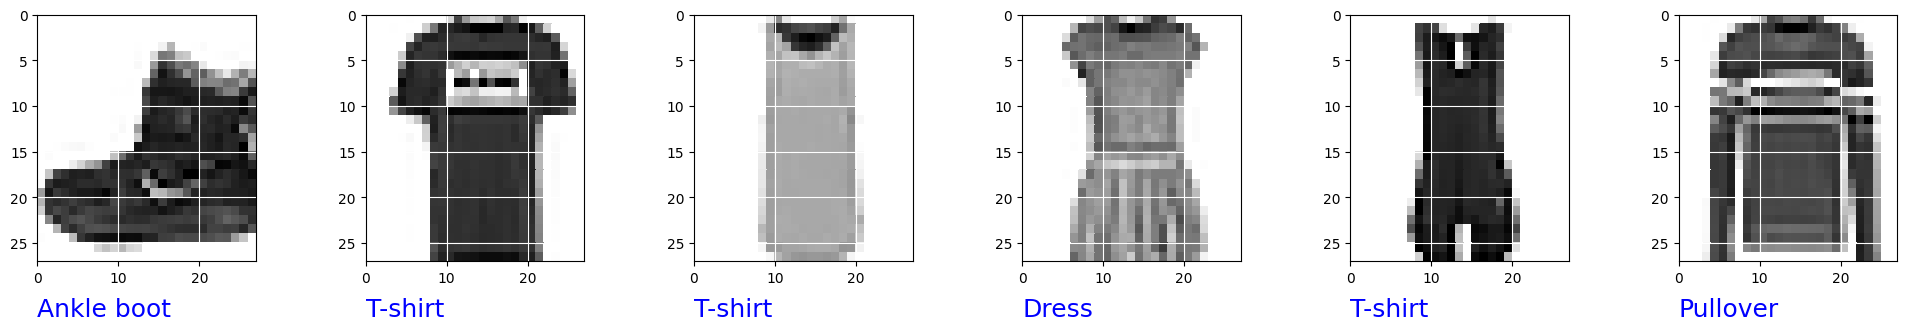

In [3]:
# 이미지로 출력
plt.figure(figsize=(24, 3.2))
plt.subplots_adjust(wspace=0.5)
plt.gray()

for id in range(6):
    plt.subplot(1, 6, id + 1)
    img = x_train_raw[id, :, :]
    plt.pcolor(255 - img)
    plt.text(0, 33, "%s" % label_name[y_train_raw[id]], color='blue', fontsize=18)

    plt.xlim(0, 27)
    plt.ylim(27, 0)

    plt.grid('on', color='white')
plt.show()

## 3. 실험 모델 정의

- A: 합성곱 1층 + Dense 64
- B: 합성곱 2층 + Dense 64
- C: 합성곱 2층 + Dense 128 + Dropout 0.3

C는 Dense 크기도 변경하므로 Dropout만의 효과로 해석하지 않음.

In [4]:
def build_model_a():
    # 기준 CNN
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ])
    return model


def build_model_b():
    # 합성곱 층을 하나 더 추가한 CNN
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ])
    return model


def build_model_c():
    # Dense 크기를 늘리고 Dropout을 적용한 CNN
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax'),
    ])
    return model


## 4. 학습 함수

In [5]:
def train_and_evaluate(name, model, epochs=3, batch_size=128):
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )
    print('')
    print('====', name, '====')
    model.summary()

    start_time = time.time()
    history = model.fit(
        x_train_cnn,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(x_val_cnn, y_val),
        verbose=0,
    )
    elapsed_time = time.time() - start_time

    val_loss, val_acc = model.evaluate(x_val_cnn, y_val, verbose=0)
    print(name, 'validation loss:', val_loss)
    print(name, 'validation accuracy:', val_acc)
    print('computation time: {:.3f} sec'.format(elapsed_time))
    return history, val_loss, val_acc, model, elapsed_time


## 5. 기본 모델 A/B/C 학습

In [6]:
EPOCHS = 30

experiments = {}
basic_experiments = {}

history_a, loss_a, acc_a, model_a, time_a = train_and_evaluate('Model A - basic CNN', build_model_a(), EPOCHS)
experiments['Model A'] = {'history': history_a, 'loss': loss_a, 'acc': acc_a, 'model': model_a, 'time': time_a}
basic_experiments['Model A'] = experiments['Model A']

history_b, loss_b, acc_b, model_b, time_b = train_and_evaluate('Model B - deeper CNN', build_model_b(), EPOCHS)
experiments['Model B'] = {'history': history_b, 'loss': loss_b, 'acc': acc_b, 'model': model_b, 'time': time_b}
basic_experiments['Model B'] = experiments['Model B']

history_c, loss_c, acc_c, model_c, time_c = train_and_evaluate('Model C - dropout CNN', build_model_c(), EPOCHS)
experiments['Model C'] = {'history': history_c, 'loss': loss_c, 'acc': acc_c, 'model': model_c, 'time': time_c}
basic_experiments['Model C'] = experiments['Model C']

basic_best_name = max(basic_experiments, key=lambda n: basic_experiments[n]['acc'])
basic_best_result = basic_experiments[basic_best_name]

print('')
print('Best basic model:', basic_best_name)


==== Model A - basic CNN ====
Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 28, 28, 16)        160       


 max_pooling2d (MaxPooling2D  (None, 14, 14, 16)       0         


...

Total params: 206,922


Trainable params: 206,922


Non-trainable params: 0


_________________________________________________________________


Model C - dropout CNN validation loss: 0.2730339467525482
Model C - dropout CNN validation accuracy: 0.9251999855041504
computation time: 241.683 sec

Best basic model: Model C


## 6. 기본 모델 A/B/C 결과

이번 저장 결과는 개별 학습 시간 합계와 전체 실행 시간이 일치하지 않아 시간 및 accuracy/time 비교에서 제외. 검증 정확도와 손실로 모델 비교.

In [7]:
print('[기본 모델 A/B/C 비교]')
for name, result in basic_experiments.items():
    print('{0}: validation accuracy={1:.4f}, validation loss={2:.4f}, time={3:.3f} sec, accuracy/time={4:.6f}'.format(
        name, result['acc'], result['loss'], result['time'], result['acc'] / result['time']))

print('')
print('Best basic model:', basic_best_name)


[기본 모델 A/B/C 비교]
Model A: validation accuracy=0.9176, validation loss=0.3609, time=249.758 sec, accuracy/time=0.003674
Model B: validation accuracy=0.9204, validation loss=0.2975, time=2480.606 sec, accuracy/time=0.000371
Model C: validation accuracy=0.9252, validation loss=0.2730, time=241.683 sec, accuracy/time=0.003828

Best basic model: Model C


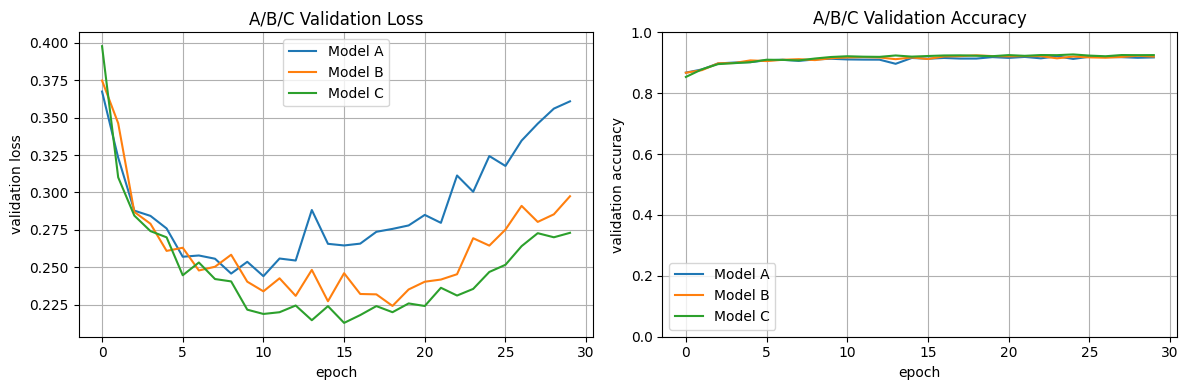

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for name, result in basic_experiments.items():
    plt.plot(result['history'].history['val_loss'], label=name)
plt.xlabel('epoch')
plt.ylabel('validation loss')
plt.title('A/B/C Validation Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
for name, result in basic_experiments.items():
    plt.plot(result['history'].history['val_accuracy'], label=name)
plt.xlabel('epoch')
plt.ylabel('validation accuracy')
plt.title('A/B/C Validation Accuracy')
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

## 7. 최종 모델 선택

In [9]:
best_name = basic_best_name
best_model = basic_best_result['model']

print('[최종 모델 선택]')
print('Best model:', best_name)
print('validation accuracy={0:.4f}'.format(basic_best_result['acc']))
print('validation loss={0:.4f}'.format(basic_best_result['loss']))
print('time={0:.3f} sec'.format(basic_best_result['time']))
print('accuracy/time={0:.6f}'.format(basic_best_result['acc'] / basic_best_result['time']))

# 모델 선택을 끝낸 뒤 테스트 데이터로 한 번 평가
final_test_loss, final_test_acc = best_model.evaluate(x_test_cnn, y_test, verbose=0)
print('Final test loss: {:.4f}'.format(final_test_loss))
print('Final test accuracy: {:.4f}'.format(final_test_acc))


[최종 모델 선택]
Best model: Model C
validation accuracy=0.9252
validation loss=0.2730
time=241.683 sec
accuracy/time=0.003828


Final test loss: 0.3118
Final test accuracy: 0.9198


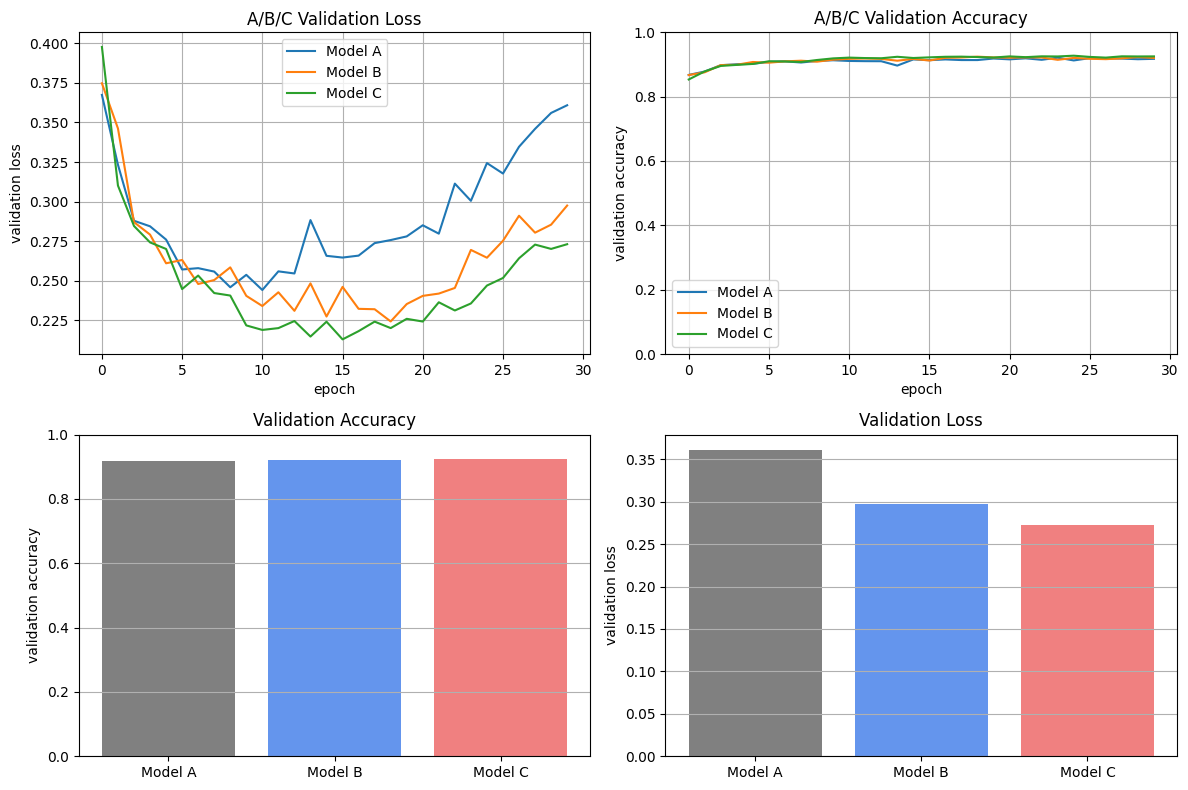

In [10]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
for name, result in basic_experiments.items():
    plt.plot(result['history'].history['val_loss'], label=name)
plt.xlabel('epoch')
plt.ylabel('validation loss')
plt.title('A/B/C Validation Loss')
plt.grid(True)
plt.legend()

plt.subplot(2, 2, 2)
for name, result in basic_experiments.items():
    plt.plot(result['history'].history['val_accuracy'], label=name)
plt.xlabel('epoch')
plt.ylabel('validation accuracy')
plt.title('A/B/C Validation Accuracy')
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

model_names = list(basic_experiments.keys())
model_acc = [basic_experiments[name]['acc'] for name in model_names]
model_loss = [basic_experiments[name]['loss'] for name in model_names]

plt.subplot(2, 2, 3)
plt.bar(model_names, model_acc, color=['gray', 'cornflowerblue', 'lightcoral'])
plt.ylabel('validation accuracy')
plt.title('Validation Accuracy')
plt.ylim(0, 1)
plt.grid(True, axis='y')

plt.subplot(2, 2, 4)
plt.bar(model_names, model_loss, color=['gray', 'cornflowerblue', 'lightcoral'])
plt.ylabel('validation loss')
plt.title('Validation Loss')
plt.grid(True, axis='y')

plt.tight_layout()
plt.show()


## 8. 예측 결과 분석

wrong count: 802 / 10000
best accuracy from wrong count: 0.9198


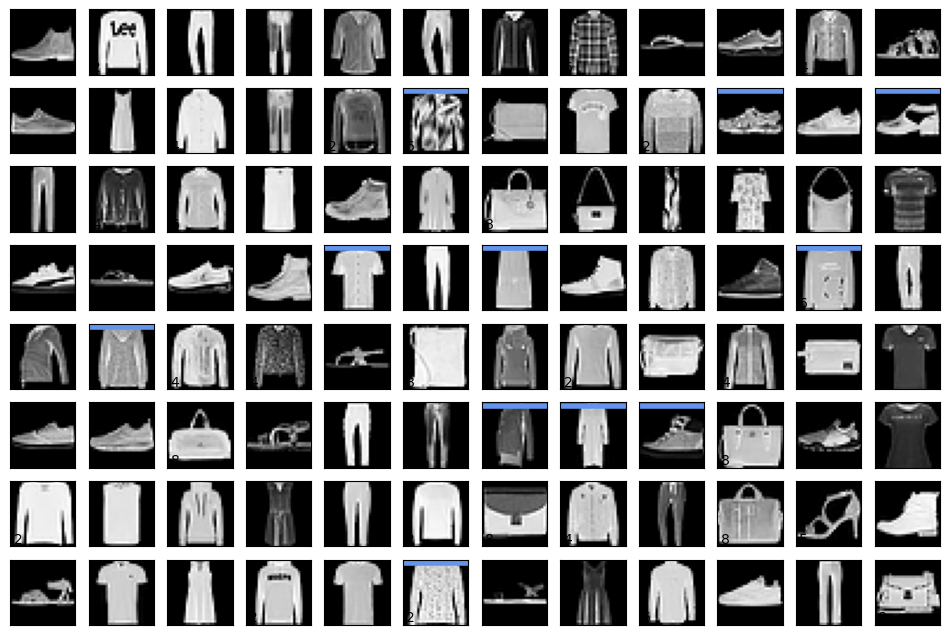

In [11]:
y_pred = best_model.predict(x_test_cnn, verbose=0)
pred_label = np.argmax(y_pred, axis=1)
true_label = y_test_raw
wrong_idx = np.where(pred_label != true_label)[0]

print('wrong count:', len(wrong_idx), '/', len(true_label))
print('best accuracy from wrong count:', 1 - len(wrong_idx) / len(true_label))

plt.figure(figsize=(12, 8))
plt.gray()
for i in range(96):
    plt.subplot(8, 12, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.text(1, 26, str(pred_label[i]), fontsize=10, color='black')
    if pred_label[i] != true_label[i]:
        plt.plot([0, 27], [1, 1], color='cornflowerblue', linewidth=4)
    plt.xticks([])
    plt.yticks([])
plt.show()